<a href="https://colab.research.google.com/github/qhfl3644/team10-recsys/blob/main/notebooks/09_final_eval.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 09. 결과 통합 + 성공 기준 판정 (C3~C6) — 김율이

세 사람 결과(`predictions/`, `results/{baselines,mf,cbf,hybrid,attack}/`)를 한 번에 읽어 **같은 함수로 다시 채점**하고,
성공 기준 ①~⑥ 판정표와 발표용 표·그래프를 `results/final/`에 저장한다.

| 셀 | 내용 | 출력 (`results/final/`) |
|---|---|---|
| 1 | 평점 예측 통합표 (데이터셋 × 모델 × 범위 all/seen × 구간) | `rating_test_all.csv` |
| 2 | 성공 기준 ①·②·④ (paired 부트스트랩 CI) | `criteria_rating.csv` |
| 3 | 랭킹 통합표 (①②③, p3_users 공통 표본) + 성공 기준 ③ | `ranking_test_all.csv`, `criteria_rank.csv` |
| 4 | 콜드스타트 구간 분석 (C3) 그래프 | `fig_cold_rmse.png`, `fig_cold_hr.png` |
| 5 | 프로토콜 비교 (제안서 5.2절) 그래프 | `fig_protocols.png` |
| 6 | 공격·탐지·회복 요약, 성공 기준 ⑤⑥ | `criteria_attack.csv` |
| 7 | 최종 판정표 | `criteria_summary.csv`, `criteria_summary.json` |

없는 파일(예: Toys 공격 결과)은 건너뛰고 표시만 한다. 규칙: `docs/EVAL_RULES.md`.

In [2]:
# ===== 0. 설정 =====
import os, sys, subprocess, json, time, warnings
try:
    from google.colab import drive
    drive.mount('/content/drive')
    REPO = '/content/team10-recsys'
    if not os.path.exists(REPO):
        subprocess.run(['git', 'clone', '-q', 'https://github.com/qhfl3644/team10-recsys.git', REPO], check=True)
    else:
        subprocess.run(['git', '-C', REPO, 'pull', '-q'], check=True)
except ImportError:
    REPO = os.environ.get('TEAM10_REPO', '..')
sys.path.insert(0, REPO)
from config import *

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.eval import metrics as M

OUT = f'{RESULT_DIR}/final'
os.makedirs(OUT, exist_ok=True)
RATING_MODELS = ['global_mean', 'user_mean', 'item_mean', 'mf', 'mf_fb', 'cbf', 'hybrid', 'hybrid_grp']
RANK_ORDER = ['popularity', 'cbf', 'mf', 'rank_hybrid', 'rank_hybrid_retuned']
COLOR = {'Video_Games': '#2a78d6', 'Toys_and_Games': '#eb6834'}
plt.rcParams.update({'figure.facecolor': 'white', 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '#e4e3df', 'axes.axisbelow': True, 'font.size': 10,
                     'axes.titleweight': 'bold', 'legend.frameon': False})

def have(path):
    ok = os.path.exists(path)
    if not ok:
        print(f'  (없음) {path}')
    return ok

data = {ds: M.load_data(ds) for ds in DATASETS}
print({ds: f'users={d.n_users:,} items={d.n_items:,}' for ds, d in data.items()})

Mounted at /content/drive
{'Video_Games': 'users=94,762 items=25,612', 'Toys_and_Games': 'users=432,264 items=162,035'}


## 1. 평점 예측 통합표

`predictions/{ds}/{모델}_test.parquet`를 전부 읽어 **같은 `rating_table`로 다시 계산**한다.
`mf` = 순수 MF(train에 없는 상품은 μ + b_u), `mf_fb` = 그 행만 CBF로 바꾼 버전. `scope=seen`은 train에 있는 상품의 평점만.

In [3]:
# ===== 1. 평점 통합표 =====
preds, rating_tables = {}, []
for ds in DATASETS:
    preds[ds] = {}
    for m in RATING_MODELS:
        p = f'{PRED_DIR}/{ds}/{m}_test.parquet'
        if have(p):
            preds[ds][m] = M.load_predictions(ds, m, 'test', data[ds].test)
    rt = M.rating_table(preds[ds], data[ds].test, data[ds]); rt.insert(0, 'dataset', ds)
    rating_tables.append(rt)
    print(f'{ds}: 모델 {list(preds[ds])}')
rating_all = pd.concat(rating_tables, ignore_index=True)
rating_all.to_csv(f'{OUT}/rating_test_all.csv', index=False)

print('\n[test RMSE, scope=all]')
print(rating_all[rating_all.scope == 'all'].pivot_table(index=['dataset', 'model'], columns='group', values='rmse',
                                                       sort=False).reindex(columns=['all'] + M.GROUPS).round(4).to_string())
print('\n[test RMSE, scope=seen (순수 MF 비교용), group=all]')
print(rating_all[(rating_all.scope == 'seen') & (rating_all.group == 'all')].pivot_table(index='model', columns='dataset', values='rmse', sort=False).round(4).to_string())

Video_Games: 모델 ['global_mean', 'user_mean', 'item_mean', 'mf', 'mf_fb', 'cbf', 'hybrid', 'hybrid_grp']
Toys_and_Games: 모델 ['global_mean', 'user_mean', 'item_mean', 'mf', 'mf_fb', 'cbf', 'hybrid', 'hybrid_grp']

[test RMSE, scope=all]
group                          all  cold(3-4)  mid(5-9)  active(10+)
dataset        model                                                
Video_Games    global_mean  1.2949     1.3046    1.2860       1.2812
               user_mean    1.2466     1.2896    1.2107       1.1737
               item_mean    1.2677     1.2749    1.2617       1.2564
               mf           1.1714     1.1912    1.1574       1.1331
               mf_fb        1.1717     1.1917    1.1575       1.1330
               cbf          1.2890     1.3418    1.2493       1.1874
               hybrid       1.1701     1.1908    1.1555       1.1306
               hybrid_grp   1.1698     1.1901    1.1555       1.1307
Toys_and_Games global_mean  1.2566     1.2782    1.2554       1.1914
      

## 2. 성공 기준 ①·②·④ (평점 트랙)

- ①(VG)·④(Toys): 모델 RMSE < 기준 모델 3개 (점추정), 차이의 95% CI 보고. 대표 모델은 `hybrid`, 참고로 `mf`도 판정
- ②: cold(3~4) 구간에서 (단일 − 하이브리드) CI 상한 ≥ 0 → 통과. 단일 = `mf_fb`, `cbf`. 두 데이터셋 모두 통과해야 함

In [4]:
# ===== 2. 기준 ①②④ =====
rows = []
for ds in DATASETS:
    P = preds[ds]; d = data[ds]
    base = {k: P[k] for k in ['global_mean', 'user_mean', 'item_mean'] if k in P}
    cname = '①' if ds == DATASETS[0] else '④'
    for m in ['hybrid', 'mf', 'mf_fb']:
        if m not in P: continue
        for scope in (['all', 'seen'] if m == 'mf' else ['all']):
            t = M.criterion_rating_vs_baselines(P[m], base, d.test, d, scope=scope)
            for r in t.to_dict('records'):
                rows.append(dict(criterion=cname, dataset=ds, model=m, scope=scope, vs=r['baseline'], rmse_model=r['rmse_model'],
                                 rmse_vs=r['rmse_baseline'], diff=r['baseline_minus_model'], ci_lo=r['ci_lo'], ci_hi=r['ci_hi'], passed=r['passed']))
            print(f"[기준 {cname}] {ds} {m} ({scope}): {'통과' if t.attrs['passed'] else '실패'}  RMSE {t.rmse_model.iloc[0]:.4f} vs 기준 모델 최저 {t.rmse_baseline.min():.4f}")
    singles = {k: P[k] for k in ['mf_fb', 'cbf'] if k in P}
    for h in ['hybrid', 'hybrid_grp']:
        if h not in P or not singles: continue
        t = M.criterion_cold_hybrid(P[h], singles, d.test, d)
        for r in t.to_dict('records'):
            rows.append(dict(criterion='②', dataset=ds, model=h, scope='cold(3-4)', vs=r['single'], rmse_model=r['rmse_hybrid'],
                             rmse_vs=r['rmse_single'], diff=r['single_minus_hybrid'], ci_lo=r['ci_lo'], ci_hi=r['ci_hi'], passed=r['passed']))
        print(f"[기준 ②] {ds} {h}: {'통과' if t.attrs['passed'] else '실패'}  " + '; '.join(f"vs {r['single']} 차이 {r['single_minus_hybrid']:+.4f} [{r['ci_lo']:+.4f}, {r['ci_hi']:+.4f}]" for r in t.to_dict('records')))
criteria_rating = pd.DataFrame(rows)
criteria_rating.to_csv(f'{OUT}/criteria_rating.csv', index=False)

[기준 ①] Video_Games hybrid (all): 통과  RMSE 1.1701 vs 기준 모델 최저 1.2466
[기준 ①] Video_Games mf (all): 통과  RMSE 1.1714 vs 기준 모델 최저 1.2466
[기준 ①] Video_Games mf (seen): 통과  RMSE 1.1706 vs 기준 모델 최저 1.2460
[기준 ①] Video_Games mf_fb (all): 통과  RMSE 1.1717 vs 기준 모델 최저 1.2466
[기준 ②] Video_Games hybrid: 통과  vs mf_fb 차이 +0.0010 [-0.0001, +0.0020]; vs cbf 차이 +0.1510 [+0.1451, +0.1573]
[기준 ②] Video_Games hybrid_grp: 통과  vs mf_fb 차이 +0.0016 [+0.0009, +0.0023]; vs cbf 차이 +0.1517 [+0.1454, +0.1582]
[기준 ④] Toys_and_Games hybrid (all): 통과  RMSE 1.1495 vs 기준 모델 최저 1.2173
[기준 ④] Toys_and_Games mf (all): 통과  RMSE 1.1472 vs 기준 모델 최저 1.2173
[기준 ④] Toys_and_Games mf (seen): 통과  RMSE 1.1463 vs 기준 모델 최저 1.2164
[기준 ④] Toys_and_Games mf_fb (all): 통과  RMSE 1.1474 vs 기준 모델 최저 1.2173
[기준 ②] Toys_and_Games hybrid: 실패  vs mf_fb 차이 -0.0026 [-0.0031, -0.0021]; vs cbf 차이 +0.1502 [+0.1476, +0.1529]
[기준 ②] Toys_and_Games hybrid_grp: 실패  vs mf_fb 차이 -0.0009 [-0.0012, -0.0006]; vs cbf 차이 +0.1519 [+0.1491, +0.1548]


## 3. 랭킹 통합표 + 성공 기준 ③

지훈님 08 노트북이 저장한 사용자별 hit(`results/hybrid/{ds}_ranking_hits_test.parquet`)과
기준 모델 hit을 **같은 사용자(p3_users)** 로 맞춰 HR@10을 다시 계산하고, 기준 ③은 `criterion_topn_vs_popularity`로 판정한다.
기준 모델 4개의 hit은 여기서 다시 계산한다(수 분).

In [5]:
# ===== 3. 랭킹 통합표 =====
from src.models.baselines import BASELINES
hits_all, rank_rows, crit3 = {}, [], []
for ds in DATASETS:
    d = data[ds]; p3 = M.load_p3_users(ds); hits = {}
    hp = f'{RESULT_DIR}/hybrid/{ds}_ranking_hits_test.parquet'
    if have(hp):
        hl = pd.read_parquet(hp)
        for (m, pr), g in hl.groupby(['model', 'protocol']):
            hits[(m, pr)] = pd.Series(g['hit'].values, index=g['uidx'].values).sort_index()
    t0 = time.time()
    base_models = {k: cls().fit(d.train, d.n_users, d.n_items) for k, cls in BASELINES.items()}
    _, bh = M.ranking_eval(base_models, d, 'test', users=p3)
    for (m, pr), s in bh.items():
        hits.setdefault((m, pr), s.sort_index())          # 지훈님 파일에 있으면 그걸 우선
    print(f'{ds}: 기준 모델 랭킹 재계산 ({time.time()-t0:.0f}초), 모델 {sorted({m for m, _ in hits})}')
    hits_all[ds] = hits
    for (m, pr), s in hits.items():
        rank_rows.append(dict(dataset=ds, model=m, protocol=pr, n_users=len(s), HR10=float(s.mean())))
    if ('rank_hybrid', 'p3') in hits:
        c = M.criterion_topn_vs_popularity(hits, hybrid='rank_hybrid'); c.update(dataset=ds, model='rank_hybrid'); crit3.append(c)
        print(f"[기준 ③] {ds}: {'통과' if c['passed'] else '실패'}  HR@10 {c['hr_hybrid']:.4f} vs 인기도 {c['hr_popularity']:.4f}, 차이 {c['hybrid_minus_popularity']:+.4f} [{c['ci_lo']:+.4f}, {c['ci_hi']:+.4f}]")
    if ('rank_hybrid_retuned', 'p3') in hits:
        c = M.criterion_topn_vs_popularity(hits, hybrid='rank_hybrid_retuned'); c.update(dataset=ds, model='rank_hybrid_retuned'); crit3.append(c)
ranking_all = pd.DataFrame(rank_rows)
ranking_all.to_csv(f'{OUT}/ranking_test_all.csv', index=False)
criteria_rank = pd.DataFrame(crit3); criteria_rank.to_csv(f'{OUT}/criteria_rank.csv', index=False)
order = [m for m in RANK_ORDER + sorted(set(ranking_all.model) - set(RANK_ORDER))]
print('\n[HR@10, p3_users 공통 표본]')
print(ranking_all.pivot_table(index=['dataset', 'model'], columns='protocol', values='HR10').reindex(
    [(ds, m) for ds in DATASETS for m in order if (ds, m) in set(zip(ranking_all.dataset, ranking_all.model))]).round(4).to_string())

Video_Games: 기준 모델 랭킹 재계산 (13초), 모델 ['cbf', 'global_mean', 'item_mean', 'mf', 'popularity', 'rank_hybrid', 'user_mean']
[기준 ③] Video_Games: 통과  HR@10 0.0366 vs 인기도 0.0248, 차이 +0.0118 [+0.0075, +0.0160]
Toys_and_Games: 기준 모델 랭킹 재계산 (66초), 모델 ['global_mean', 'item_mean', 'popularity', 'rank_hybrid', 'rank_hybrid_retuned', 'user_mean']
[기준 ③] Toys_and_Games: 통과  HR@10 0.0171 vs 인기도 0.0038, 차이 +0.0133 [+0.0106, +0.0160]

[HR@10, p3_users 공통 표본]
protocol                                p1      p2      p3
dataset        model                                      
Video_Games    popularity           0.4919  0.1660  0.0248
               cbf                  0.4055  0.3787  0.0159
               mf                   0.1099  0.1097  0.0002
               rank_hybrid          0.5832  0.3056  0.0366
               global_mean          0.0983  0.0983  0.0006
               item_mean            0.0542  0.1157  0.0003
               user_mean            0.0983  0.0983  0.0006
Toys_and_Games popularit

## 4. 콜드스타트 구간 분석 (C3)

평점 트랙(RMSE)과 Top-N 트랙(③ HR@10)을 학습 평점 수 구간별로 본다.

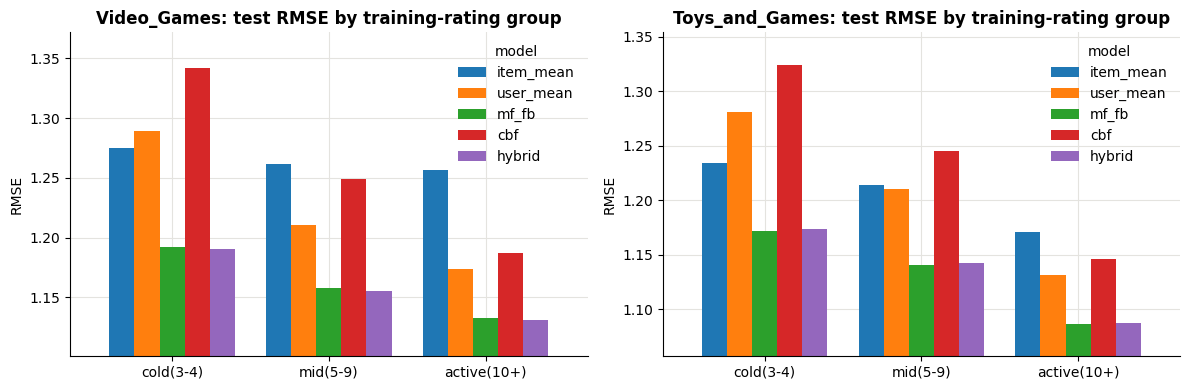

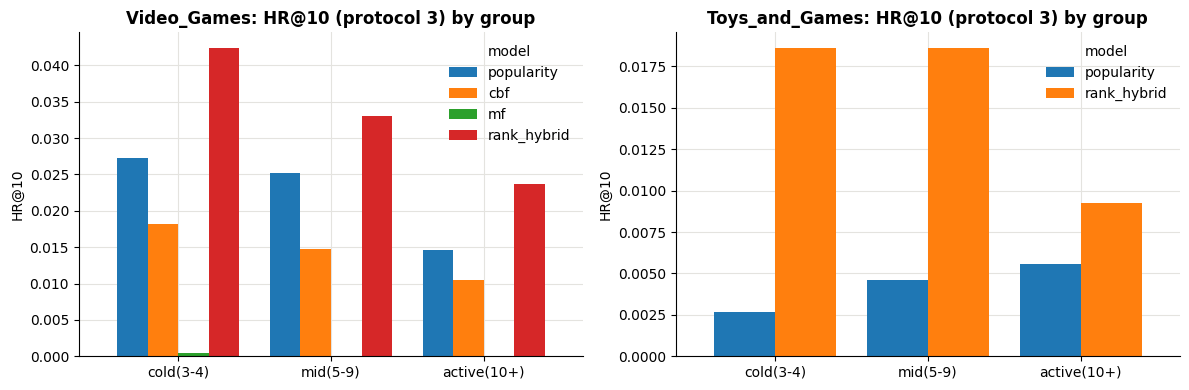

model                          cbf      mf  popularity  rank_hybrid
dataset        group                                               
Toys_and_Games active(10+)     NaN     NaN      0.0056       0.0093
               cold(3-4)       NaN     NaN      0.0027       0.0186
               mid(5-9)        NaN     NaN      0.0046       0.0186
Video_Games    active(10+)  0.0104  0.0000      0.0146       0.0236
               cold(3-4)    0.0182  0.0004      0.0273       0.0424
               mid(5-9)     0.0147  0.0000      0.0252       0.0330


In [6]:
# ===== 4. 콜드스타트 =====
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=False)
for ax, ds in zip(axes, DATASETS):
    t = rating_all[(rating_all.dataset == ds) & (rating_all.scope == 'all') & (rating_all.group != 'all')]
    show = [m for m in ['item_mean', 'user_mean', 'mf_fb', 'cbf', 'hybrid'] if m in set(t.model)]
    pv = t.pivot_table(index='group', columns='model', values='rmse').reindex(M.GROUPS)[show]
    pv.plot.bar(ax=ax, width=0.8, rot=0); ax.set_title(f'{ds}: test RMSE by training-rating group'); ax.set_xlabel(''); ax.set_ylabel('RMSE')
    ax.set_ylim(pv.values.min() - 0.03, pv.values.max() + 0.03)
plt.tight_layout(); plt.savefig(f'{OUT}/fig_cold_rmse.png', dpi=200, bbox_inches='tight'); plt.show()

cold_hr = []
for ds in DATASETS:
    grp = pd.Series(data[ds].group_of(np.arange(data[ds].n_users)))
    for m in ['popularity', 'cbf', 'mf', 'rank_hybrid']:
        s = hits_all[ds].get((m, 'p3'))
        if s is None: continue
        g = grp.reindex(s.index).values
        for gname in M.GROUPS:
            cold_hr.append(dict(dataset=ds, model=m, group=gname, n=int((g == gname).sum()), HR10_p3=float(s.values[g == gname].mean())))
cold_hr = pd.DataFrame(cold_hr); cold_hr.to_csv(f'{OUT}/cold_hr_p3.csv', index=False)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, ds in zip(axes, DATASETS):
    pv = cold_hr[cold_hr.dataset == ds].pivot_table(index='group', columns='model', values='HR10_p3').reindex(M.GROUPS)
    pv = pv[[m for m in ['popularity', 'cbf', 'mf', 'rank_hybrid'] if m in pv.columns]]
    pv.plot.bar(ax=ax, width=0.8, rot=0); ax.set_title(f'{ds}: HR@10 (protocol 3) by group'); ax.set_xlabel(''); ax.set_ylabel('HR@10')
plt.tight_layout(); plt.savefig(f'{OUT}/fig_cold_hr.png', dpi=200, bbox_inches='tight'); plt.show()
print(cold_hr.pivot_table(index=['dataset', 'group'], columns='model', values='HR10_p3').round(4).to_string())

## 5. 프로토콜 비교 (제안서 5.2절)

같은 모델의 HR@10이 ①②③에서 어떻게 달라지고, **모델 순위가 뒤집히는지** 본다. 프로토콜마다 난이도가 달라 절대값은 같은 프로토콜 안에서만 비교한다.

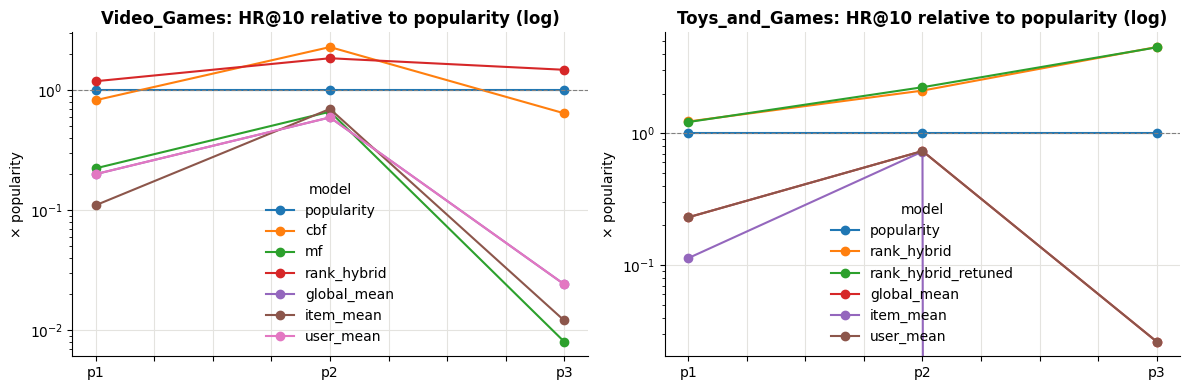

protocol                             p1   p2   p3
dataset        model                             
Toys_and_Games global_mean          4.0  4.0  4.0
               item_mean            6.0  6.0  6.0
               popularity           3.0  3.0  3.0
               rank_hybrid          1.0  2.0  1.0
               rank_hybrid_retuned  2.0  1.0  2.0
               user_mean            4.0  4.0  4.0
Video_Games    cbf                  3.0  1.0  3.0
               global_mean          5.0  6.0  4.0
               item_mean            7.0  4.0  6.0
               mf                   4.0  5.0  7.0
               popularity           2.0  3.0  2.0
               rank_hybrid          1.0  2.0  1.0
               user_mean            5.0  6.0  4.0


In [7]:
# ===== 5. 프로토콜 비교 =====
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, ds in zip(axes, DATASETS):
    pv = ranking_all[ranking_all.dataset == ds].pivot_table(index='model', columns='protocol', values='HR10')
    pv = pv.reindex([m for m in order if m in pv.index])
    rel = pv.div(pv.loc['popularity'], axis=1)           # 인기도 대비 배수
    rel.T.plot(ax=ax, marker='o', logy=True); ax.set_title(f'{ds}: HR@10 relative to popularity (log)'); ax.set_ylabel('× popularity'); ax.set_xlabel('')
    ax.axhline(1, color='gray', lw=0.8, ls='--')
plt.tight_layout(); plt.savefig(f'{OUT}/fig_protocols.png', dpi=200, bbox_inches='tight'); plt.show()
ranks = ranking_all.copy(); ranks['rank_in_protocol'] = ranks.groupby(['dataset', 'protocol'])['HR10'].rank(ascending=False).astype(int)
print(ranks.pivot_table(index=['dataset', 'model'], columns='protocol', values='rank_in_protocol').to_string())

## 6. 공격·탐지·회복 (혜림님 06 결과 요약) → 성공 기준 ⑤⑥

⑤: 공격 규모 3% 이상 시나리오에서 결정트리 F1 ≥ 0.7 (잠정 목표). ⑥: 타깃 인기도별 회복 정도 보고(판정 없음).

In [8]:
# ===== 6. 공격 =====
attack_rows, crit5 = [], {}
for ds in DATASETS:
    p = f'{RESULT_DIR}/attack/{ds}_recovery.csv'
    if not have(p): continue
    rec = pd.read_csv(p)
    size_col = next(c for c in rec.columns if '규모' in c)
    size = rec[size_col].astype(str).str.rstrip('%').astype(float)
    big = rec[size >= 3]
    crit5[ds] = dict(dataset=ds, min_f1_3pct_plus=float(big['DT_F1'].min()), passed=bool((big['DT_F1'] >= 0.7).all()),
                     min_f1_1pct=float(rec[size < 3]['DT_F1'].min()) if (size < 3).any() else None)
    print(f"[기준 ⑤] {ds}: {'통과' if crit5[ds]['passed'] else '실패'}  3%↑ DT F1 최저 {crit5[ds]['min_f1_3pct_plus']:.3f} (1%: {crit5[ds]['min_f1_1pct']})")
    tcol = next(c for c in rec.columns if '타깃' in c)
    cols = [c for c in ['DT_재현율', '상승폭', '잔존폭', '점수_회복률', 'HR_공격후', 'HR_제거후', 'HR_회복률'] if c in rec.columns]
    summ = rec.groupby(tcol)[cols].mean().round(3); summ.insert(0, 'dataset', ds); attack_rows.append(summ.reset_index())
    print(f'[기준 ⑥] {ds}: 타깃 인기도별 평균'); print(summ.to_string())
if attack_rows:
    pd.concat(attack_rows, ignore_index=True).to_csv(f'{OUT}/criteria_attack.csv', index=False)

[기준 ⑤] Video_Games: 통과  3%↑ DT F1 최저 0.714 (1%: 0.289)
[기준 ⑥] Video_Games: 타깃 인기도별 평균
               dataset  DT_재현율    상승폭    잔존폭  점수_회복률  HR_공격후  HR_제거후  HR_회복률
타깃                                                                          
popular    Video_Games   0.926  0.106 -0.153   -1.13   0.285   0.000     1.0
unpopular  Video_Games   0.922  0.664  0.663   -0.00   0.667   0.667     0.0
  (없음) /content/drive/MyDrive/Team10_RecSys/results/attack/Toys_and_Games_recovery.csv


## 7. 최종 판정표

In [9]:
# ===== 7. 최종 판정표 =====
def pick(df, **kw):
    m = np.ones(len(df), bool)
    for k, v in kw.items(): m &= (df[k] == v).values
    return df[m]

summary = []
vg, toys = DATASETS
c1 = pick(criteria_rating, criterion='①', model='hybrid', scope='all')
summary.append(dict(기준='① 구축용 RMSE < 기준 모델 3개', 대상=f'{vg} hybrid', 통과=bool(c1.passed.all()) if len(c1) else None,
                    근거=f"RMSE {c1.rmse_model.iloc[0]:.4f} vs 최저 기준 {c1.rmse_vs.min():.4f}" if len(c1) else '파일 없음'))
c2 = pick(criteria_rating, criterion='②', model='hybrid')
summary.append(dict(기준='② cold(3-4) 하이브리드 ≤ 단일 방식 (두 데이터셋)', 대상='hybrid vs mf_fb, cbf', 통과=bool(c2.passed.all()) if len(c2) else None,
                    근거='; '.join(f"{r.dataset} vs {r.vs}: {r['diff']:+.4f} [{r.ci_lo:+.4f},{r.ci_hi:+.4f}] {'O' if r.passed else 'X'}" for _, r in c2.iterrows())))
c3 = criteria_rank[criteria_rank.model == 'rank_hybrid'] if len(criteria_rank) else criteria_rank
summary.append(dict(기준='③ Top-N 하이브리드 > 인기도 (프로토콜 ③, 두 데이터셋)', 대상='rank_hybrid', 통과=bool(c3.passed.all()) if len(c3) else None,
                    근거='; '.join(f"{r.dataset}: {r.hr_hybrid:.4f} vs {r.hr_popularity:.4f} [{r.ci_lo:+.4f},{r.ci_hi:+.4f}]" for _, r in c3.iterrows())))
c4 = pick(criteria_rating, criterion='④', model='hybrid', scope='all')
summary.append(dict(기준='④ VG 설정 그대로 Toys RMSE < 기준 모델 3개', 대상=f'{toys} hybrid', 통과=bool(c4.passed.all()) if len(c4) else None,
                    근거=f"RMSE {c4.rmse_model.iloc[0]:.4f} vs 최저 기준 {c4.rmse_vs.min():.4f}" if len(c4) else '파일 없음'))
summary.append(dict(기준='⑤ 공격 3%↑ 결정트리 F1 ≥ 0.7', 대상=', '.join(crit5) or '-', 통과=all(v['passed'] for v in crit5.values()) if crit5 else None,
                    근거='; '.join(f"{ds}: 최저 {v['min_f1_3pct_plus']:.3f}" for ds, v in crit5.items()) or '파일 없음'))
summary.append(dict(기준='⑥ 제거 후 회복 (타깃 인기도별 보고)', 대상=', '.join(crit5) or '-', 통과='보고', 근거='criteria_attack.csv'))
summary = pd.DataFrame(summary)
summary.to_csv(f'{OUT}/criteria_summary.csv', index=False)
M.save_json(dict(summary=summary.to_dict('records'), rating=criteria_rating.to_dict('records'), rank=criteria_rank.to_dict('records'), attack=crit5),
            f'{OUT}/criteria_summary.json')
pd.set_option('display.max_colwidth', 200)
print(summary.to_string(index=False))
print('\n저장 위치:', OUT, '|', sorted(os.listdir(OUT)))

                                  기준                    대상    통과                                                                                                                                                                                                           근거
               ① 구축용 RMSE < 기준 모델 3개    Video_Games hybrid  True                                                                                                                                                                                  RMSE 1.1701 vs 최저 기준 1.2466
  ② cold(3-4) 하이브리드 ≤ 단일 방식 (두 데이터셋)  hybrid vs mf_fb, cbf False Video_Games vs mf_fb: +0.0010 [-0.0001,+0.0020] O; Video_Games vs cbf: +0.1510 [+0.1451,+0.1573] O; Toys_and_Games vs mf_fb: -0.0026 [-0.0031,-0.0021] X; Toys_and_Games vs cbf: +0.1502 [+0.1476,+0.1529] O
③ Top-N 하이브리드 > 인기도 (프로토콜 ③, 두 데이터셋)           rank_hybrid  True                                                                                                          Video_Games: 0.0366 

## 다음

- `criteria_summary.csv`가 발표 "평가·분석" 슬라이드의 판정표, `fig_*.png` 3개가 그래프 후보.
- 숫자가 지훈님·혜림님 정리본과 다르면 **이 노트북 값이 기준**(같은 함수·같은 표본으로 재계산). 차이가 나면 단톡에 공유.